# Deep Learning Week 2
## Classification & Improving Neural Networks

### Assignment 2 + Mini Project 2

**Assignment:** Neural Network Comparison

**Mini Project:** Handwritten Digit Classifier

**Framework:** PyTorch

**Environment:** Google Colab

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)

PyTorch version: 2.11.0+cpu
NumPy version: 2.1.3


## Assignment 2: Neural Network Comparison

### 1. Generate a Synthetic Two-Class Dataset

We generate a synthetic dataset containing two classes.

The dataset contains two numerical features and a binary target label.

- Class 0 represents the first category.
- Class 1 represents the second category.

The dataset will be used to compare a linear classifier with a nonlinear neural network.

In [3]:
# Import dataset generation function
from sklearn.datasets import make_moons
# Generate synthetic two-class data
X, y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("First 10 labels:", y[:10])

Input shape: (1000, 2)
Target shape: (1000,)
First 10 labels: [1 1 1 1 0 1 1 1 1 0]


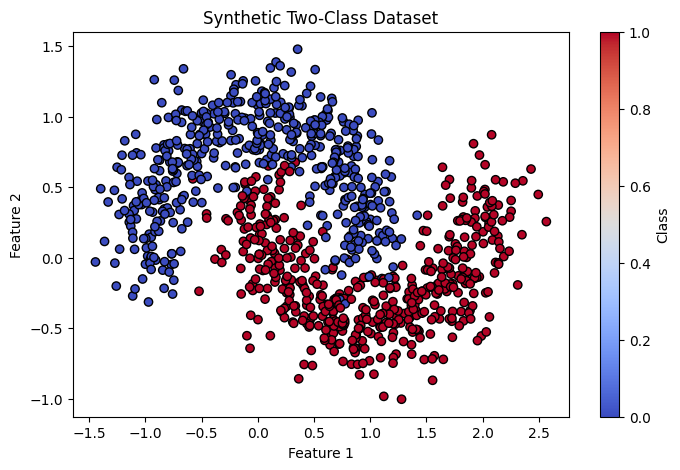

In [4]:
# Visualize the two-class dataset

plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolors="k"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Two-Class Dataset")
plt.colorbar(label="Class")

plt.show()

## 2. Split Dataset into Training, Validation and Testing Sets

The generated dataset is divided into three subsets.

- Training set: 70%
- Validation set: 15%
- Testing set: 15%

The training set is used to train the models, the validation set is used to compare model configurations, and the testing set is used for final evaluation.

In [5]:
from sklearn.model_selection import train_test_split

# First split: 70% training and 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 700
Validation samples: 150
Testing samples: 150


## 3. Convert Dataset into PyTorch Tensors

The generated data is converted into PyTorch tensors so that it can be used by neural network models.

In [6]:
  # Convert data into PyTorch tensors

X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_val = torch.tensor(y_val, dtype=torch.float32).reshape(-1, 1)
y_test = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

print("Training input shape:", X_train.shape)
print("Training target shape:", y_train.shape)

Training input shape: torch.Size([700, 2])
Training target shape: torch.Size([700, 1])


## 4. Model 1: Linear Classifier

A linear classifier uses a single linear layer to classify input data into two classes.

It takes two input features and produces one output score.

The sigmoid activation function converts the score into a probability between 0 and 1.

In [7]:
# Define a linear classifier

class LinearClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        self.linear = nn.Linear(2, 1)

    def forward(self, x):
        return self.linear(x)


linear_model = LinearClassifier()

print(linear_model)

LinearClassifier(
  (linear): Linear(in_features=2, out_features=1, bias=True)
)


## 5. Training Function

The model is trained using:

1. Forward propagation
2. Binary cross-entropy loss
3. Backpropagation
4. Adam optimizer
5. Validation loss calculation

In [8]:
# Function to train classification models

def train_classifier(model, learning_rate, epochs=100):

    criterion = nn.BCEWithLogitsLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        model.train()

        outputs = model(X_train)

        loss = criterion(outputs, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        model.eval()

        with torch.no_grad():
            val_outputs = model(X_val)
            val_loss = criterion(val_outputs, y_val)

        train_losses.append(loss.item())
        val_losses.append(val_loss.item())

    return train_losses, val_losses

In [9]:
# Train the linear classifier

linear_train_losses, linear_val_losses = train_classifier(
    linear_model,
    learning_rate=0.01,
    epochs=100
)

print("Linear model training completed!")
print("Final training loss:", linear_train_losses[-1])
print("Final validation loss:", linear_val_losses[-1])

Linear model training completed!
Final training loss: 0.5802453756332397
Final validation loss: 0.568148672580719


## 6. Model 2: Nonlinear Neural Network

A nonlinear neural network uses hidden layers and activation functions to learn complex patterns.

The model contains:

- Input layer: 2 features
- Hidden layer 1: 16 neurons
- ReLU activation
- Hidden layer 2: 8 neurons
- ReLU activation
- Output layer: 1 neuron

The ReLU activation function helps the model learn nonlinear decision boundaries.

In [10]:
# Define nonlinear neural network

class NonlinearClassifier(nn.Module):

    def __init__(self, hidden_size=16):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, 8),
            nn.ReLU(),
            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.network(x)


nonlinear_model = NonlinearClassifier(hidden_size=16)

print(nonlinear_model)

NonlinearClassifier(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
  )
)


In [11]:
# Train the nonlinear neural network

nonlinear_train_losses, nonlinear_val_losses = train_classifier(
    nonlinear_model,
    learning_rate=0.01,
    epochs=100
)

print("Nonlinear model training completed!")
print("Final training loss:", nonlinear_train_losses[-1])
print("Final validation loss:", nonlinear_val_losses[-1])

Nonlinear model training completed!
Final training loss: 0.11506803333759308
Final validation loss: 0.07593739777803421


## 7. Model Evaluation

Both models are evaluated using the test dataset.

The following classification metrics are calculated:

- Accuracy: Percentage of correct predictions.
- Precision: Proportion of predicted positive cases that are actually positive.
- Recall: Proportion of actual positive cases correctly identified.
- Confusion Matrix: Shows correct and incorrect classifications.

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

def evaluate_model(model, model_name):

    model.eval()

    with torch.no_grad():
        outputs = model(X_test)
        probabilities = torch.sigmoid(outputs)
        predictions = (probabilities >= 0.5).int()

    y_true = y_test.numpy().flatten()
    y_pred = predictions.numpy().flatten()

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)

    print(f"\n{model_name}")
    print("-" * 40)
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    return accuracy, precision, recall, confusion_matrix(y_true, y_pred)


linear_results = evaluate_model(
    linear_model,
    "Linear Classifier"
)

nonlinear_results = evaluate_model(
    nonlinear_model,
    "Nonlinear Neural Network"
)


Linear Classifier
----------------------------------------
Accuracy:  0.9000
Precision: 0.9412
Recall:    0.8533

Classification Report:
              precision    recall  f1-score   support

         0.0       0.87      0.95      0.90        75
         1.0       0.94      0.85      0.90        75

    accuracy                           0.90       150
   macro avg       0.90      0.90      0.90       150
weighted avg       0.90      0.90      0.90       150


Nonlinear Neural Network
----------------------------------------
Accuracy:  0.9733
Precision: 0.9863
Recall:    0.9600

Classification Report:
              precision    recall  f1-score   support

         0.0       0.96      0.99      0.97        75
         1.0       0.99      0.96      0.97        75

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150



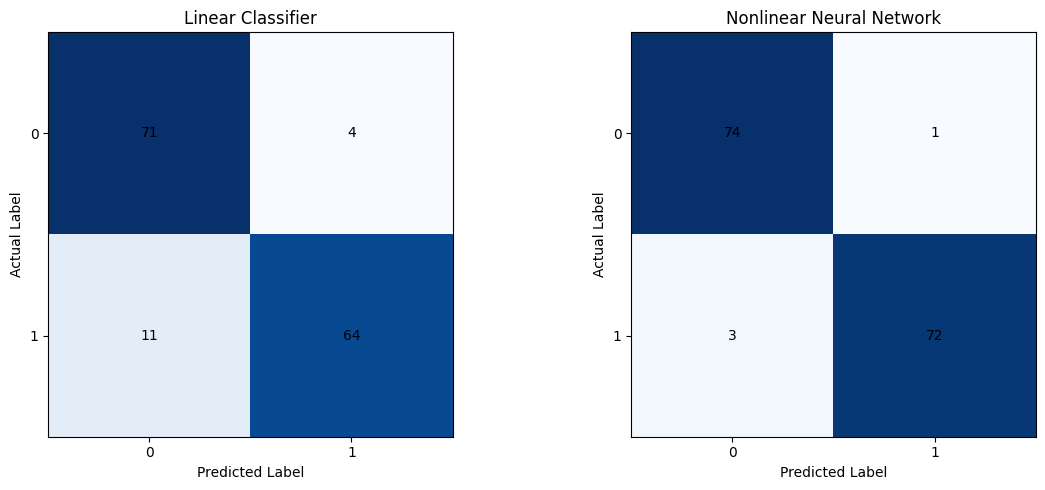

In [13]:
# Plot confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    ("Linear Classifier", linear_results[3]),
    ("Nonlinear Neural Network", nonlinear_results[3])
]

for ax, (name, cm) in zip(axes, models):

    ax.imshow(cm, cmap="Blues")

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j],
                    ha="center", va="center")

plt.tight_layout()
plt.show()

## 8. Experiment with Hidden-Layer Sizes

We experiment with different hidden-layer sizes to understand
how the number of neurons affects classification performance.

Hidden-layer sizes:
- 8 neurons
- 16 neurons
- 32 neurons

The learning rate is kept constant at 0.01.

In [14]:
# Compare different hidden-layer sizes

hidden_sizes = [8, 16, 32]
hidden_results = []

for size in hidden_sizes:

    model = NonlinearClassifier(hidden_size=size)

    train_loss, val_loss = train_classifier(
        model,
        learning_rate=0.01,
        epochs=100
    )

    model.eval()

    with torch.no_grad():
        predictions = (torch.sigmoid(model(X_val)) >= 0.5).int()

    accuracy = accuracy_score(
        y_val.numpy().flatten(),
        predictions.numpy().flatten()
    )

    hidden_results.append({
        "Hidden Neurons": size,
        "Training Loss": train_loss[-1],
        "Validation Loss": val_loss[-1],
        "Validation Accuracy": accuracy
    })

for result in hidden_results:
    print(result)

{'Hidden Neurons': 8, 'Training Loss': 0.19322088360786438, 'Validation Loss': 0.14612449705600739, 'Validation Accuracy': 0.94}
{'Hidden Neurons': 16, 'Training Loss': 0.14401978254318237, 'Validation Loss': 0.10331949591636658, 'Validation Accuracy': 0.9666666666666667}
{'Hidden Neurons': 32, 'Training Loss': 0.22728589177131653, 'Validation Loss': 0.17191274464130402, 'Validation Accuracy': 0.94}


## 9. Hidden-Layer Size Experiment: Results

Three hidden-layer sizes were tested: 8, 16 and 32 neurons.

The model with 16 hidden neurons achieved the highest validation
accuracy of 96.67% and the lowest validation loss of 0.1033.

The model with 8 neurons achieved 94% validation accuracy,
while the model with 32 neurons also achieved 94%.

The experiment shows that increasing the number of neurons does
not always improve model performance. Selecting a suitable
hidden-layer size is important.

## 10. Learning-Rate Experiment

Two learning rates are compared:

- 0.01
- 0.001

The hidden-layer size is fixed at 16 neurons.

Both models are trained for 100 epochs using the same training dataset.

In [15]:
# Compare different learning rates

learning_rates = [0.01, 0.001]
learning_rate_results = []

for lr in learning_rates:

    model = NonlinearClassifier(hidden_size=16)

    train_loss, val_loss = train_classifier(
        model,
        learning_rate=lr,
        epochs=100
    )

    model.eval()

    with torch.no_grad():
        predictions = (torch.sigmoid(model(X_val)) >= 0.5).int()

    accuracy = accuracy_score(
        y_val.numpy().flatten(),
        predictions.numpy().flatten()
    )

    learning_rate_results.append({
        "Learning Rate": lr,
        "Training Loss": train_loss[-1],
        "Validation Loss": val_loss[-1],
        "Validation Accuracy": accuracy
    })

for result in learning_rate_results:
    print(result)

{'Learning Rate': 0.01, 'Training Loss': 0.1503923535346985, 'Validation Loss': 0.10968084633350372, 'Validation Accuracy': 0.9666666666666667}
{'Learning Rate': 0.001, 'Training Loss': 0.6321284174919128, 'Validation Loss': 0.6239400506019592, 'Validation Accuracy': 0.5}


## 11. Final Model Comparison

The following experiments compare linear and nonlinear models,
different hidden-layer sizes, and different learning rates.

| Experiment | Configuration | Validation Accuracy |
|---|---|---:|
| Linear Classifier | Single linear layer | 90.00% |
| Nonlinear Classifier | 16 hidden neurons, LR 0.01 | 96.67% |
| Hidden Size | 8 neurons | 94.00% |
| Hidden Size | 16 neurons | 96.67% |
| Hidden Size | 32 neurons | 94.00% |
| Learning Rate | 0.01 | 96.67% |
| Learning Rate | 0.001 | 50.00% |

The nonlinear neural network with 16 hidden neurons and a learning
rate of 0.01 achieved the best validation accuracy among the
tested configurations.

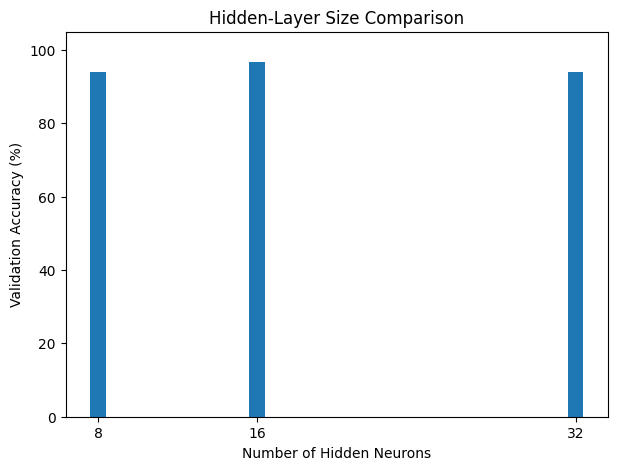

In [16]:
# Plot hidden-layer size comparison

sizes = [r["Hidden Neurons"] for r in hidden_results]
accuracies = [r["Validation Accuracy"] * 100 for r in hidden_results]

plt.figure(figsize=(7, 5))
plt.bar(sizes, accuracies)

plt.xlabel("Number of Hidden Neurons")
plt.ylabel("Validation Accuracy (%)")
plt.title("Hidden-Layer Size Comparison")
plt.xticks(sizes)
plt.ylim(0, 105)

plt.show()

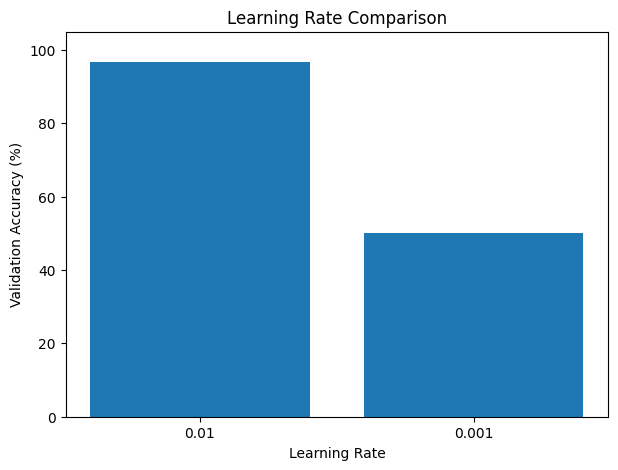

In [17]:
# Plot learning-rate comparison

rates = [
    str(r["Learning Rate"])
    for r in learning_rate_results
]

accuracies = [
    r["Validation Accuracy"] * 100
    for r in learning_rate_results
]

plt.figure(figsize=(7, 5))
plt.bar(rates, accuracies)

plt.xlabel("Learning Rate")
plt.ylabel("Validation Accuracy (%)")
plt.title("Learning Rate Comparison")
plt.ylim(0, 105)

plt.show()

## 12. Results and Discussion

The experiments demonstrate that nonlinear neural networks can
perform better than linear classifiers when the dataset contains
complex decision boundaries.

The linear classifier achieved 90% test accuracy, while the
nonlinear neural network achieved 97.33% test accuracy.

In the hidden-layer experiment, 16 neurons achieved the highest
validation accuracy of 96.67%, compared with 94% for both 8 and
32 neurons.

In the learning-rate experiment, 0.01 achieved 96.67% validation
accuracy, whereas 0.001 achieved 50% after 100 epochs.

The results show that nonlinear activation functions help neural
networks learn complex patterns. They also demonstrate that
hidden-layer size and learning rate influence model performance.

## 13. Conclusion

A binary classification problem was successfully implemented
using PyTorch and a synthetic two-class dataset.

A linear classifier and a nonlinear neural network were trained
and evaluated.

The nonlinear neural network achieved better performance because
it could learn the curved decision boundaries of the dataset.

Different hidden-layer sizes and learning rates were also tested
to understand their effects on model performance.

The experiment demonstrated the importance of nonlinear
activation functions and model configuration in classification tasks.